In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
data = pd.read_csv(r"C:\Users\DELL\Desktop\diy proj\Healthcare Analytics for Doctor Visits (1).csv")
data.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [7]:
data = pd.read_csv(r"C:\Users\DELL\Desktop\diy proj\Healthcare Analytics for Doctor Visits (1).csv") 
data.tail()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [8]:
data.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   str    
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   str    
 9   freepoor    5190 non-null   str    
 10  freerepat   5190 non-null   str    
 11  nchronic    5190 non-null   str    
 12  lchronic    5190 non-null   str    
dtypes: float64(2), int64(5), str(6)
memory usage: 609.6 KB


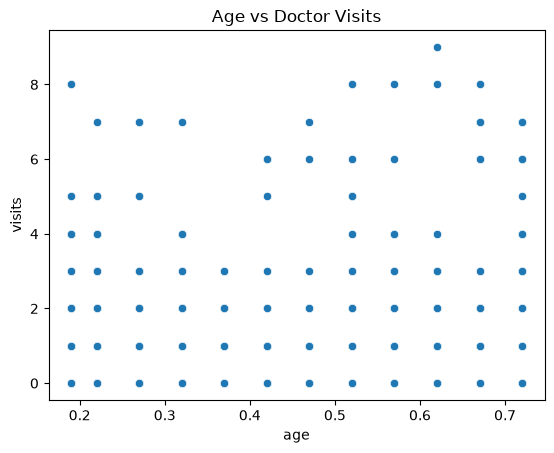

In [14]:
sns.scatterplot(x="age", y="visits", data=data)
plt.title("Age vs Doctor Visits")
plt.show()

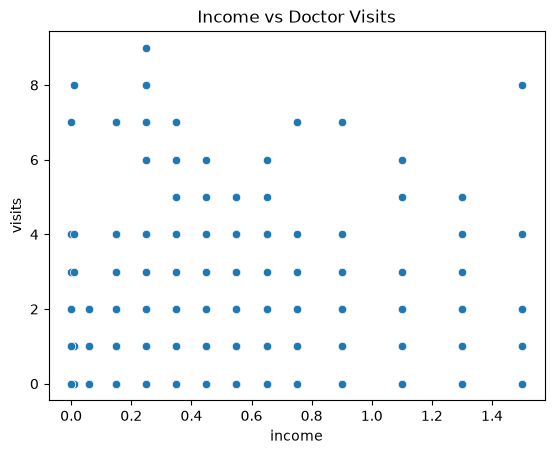

In [15]:
sns.scatterplot(x="income", y="visits", data=data)
plt.title("Income vs Doctor Visits")
plt.show()

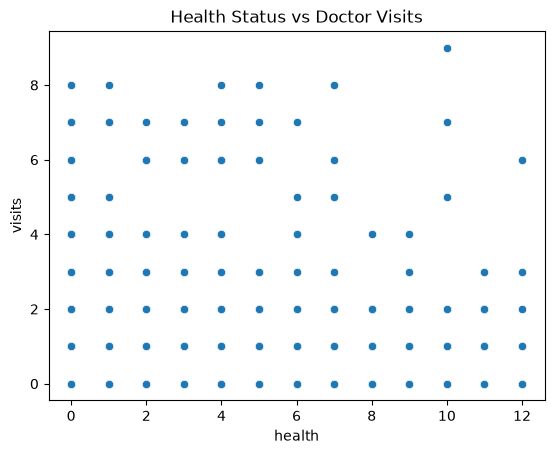

In [17]:
sns.scatterplot(x="health", y="visits", data=data)
plt.title("Health Status vs Doctor Visits")
plt.show()

In [18]:
data["high_user"] = data["visits"] > data["visits"].median()
 
print(
data.groupby("high_user")[["age","income","illness","health"]]
.mean()
)

                age    income   illness    health
high_user                                        
False      0.390336  0.598015  1.256218  1.021734
True       0.469743  0.524519  2.125834  1.990467


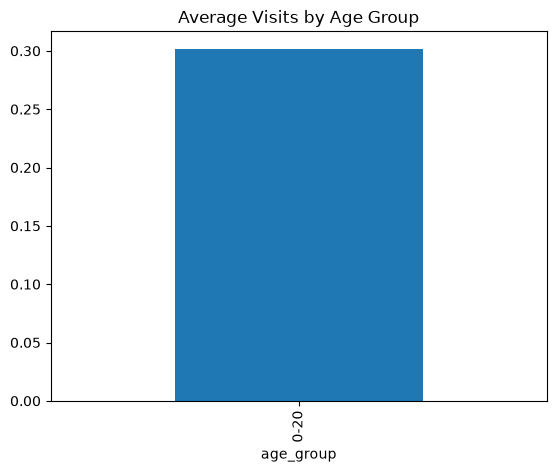

In [19]:
data["age_group"] = pd.cut(
data["age"],
bins=[0,20,40,60,80,100],
labels=["0-20","21-40","41-60","61-80","80+"]
)
 
data.groupby("age_group")["visits"].mean().plot(kind="bar")
plt.title("Average Visits by Age Group")
plt.show()

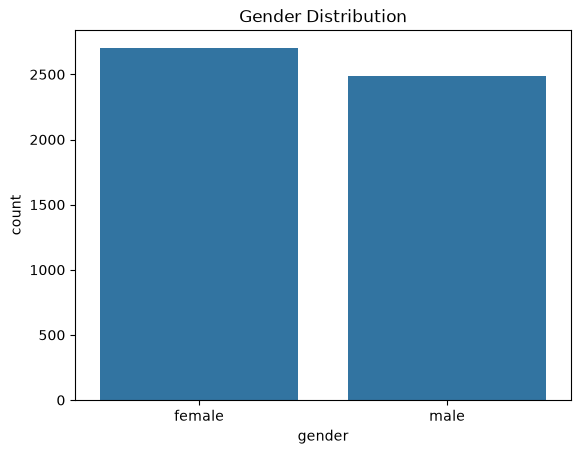

In [20]:
sns.countplot(x="gender", data=data)
plt.title("Gender Distribution")
plt.show()

In [21]:
insurance_visits = data.groupby("private")["visits"].mean()
print(insurance_visits)

private
no     0.307400
yes    0.294604
Name: visits, dtype: float64


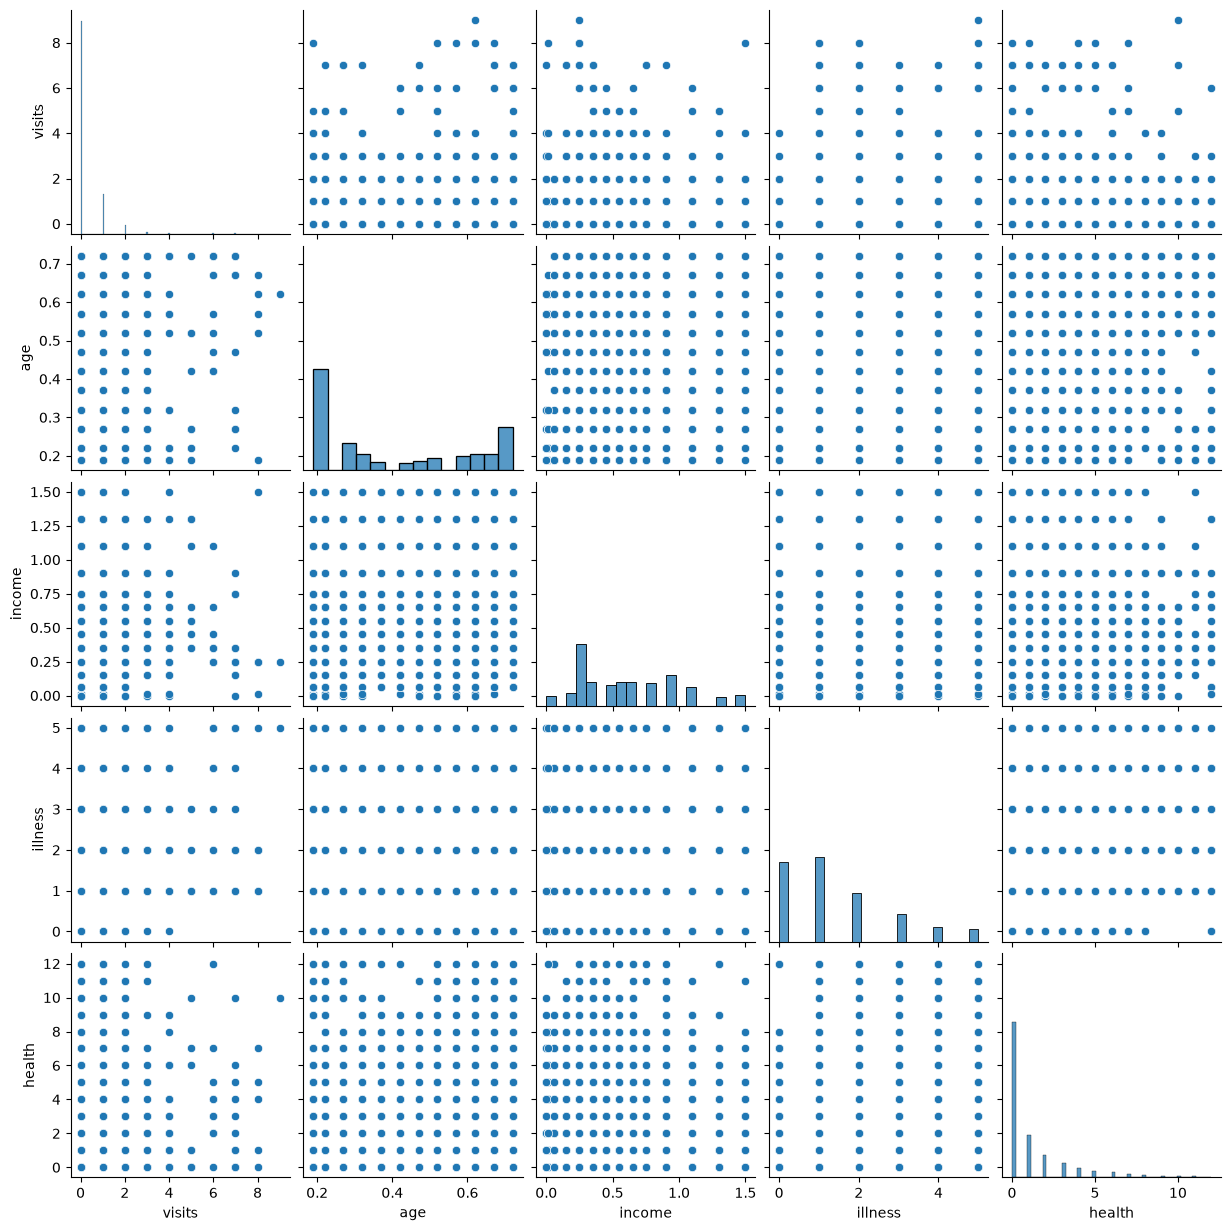

In [24]:
sns.pairplot(
data[["visits","age","income","illness","health"]]
)
plt.show()

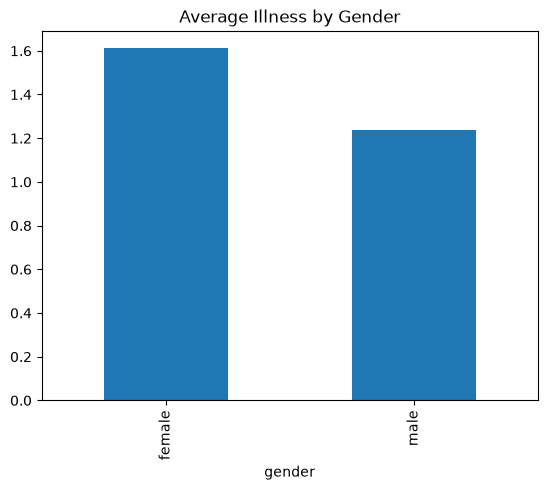

In [25]:
data.groupby("gender")["illness"].mean().plot(kind="bar")
plt.title("Average Illness by Gender")
plt.show()

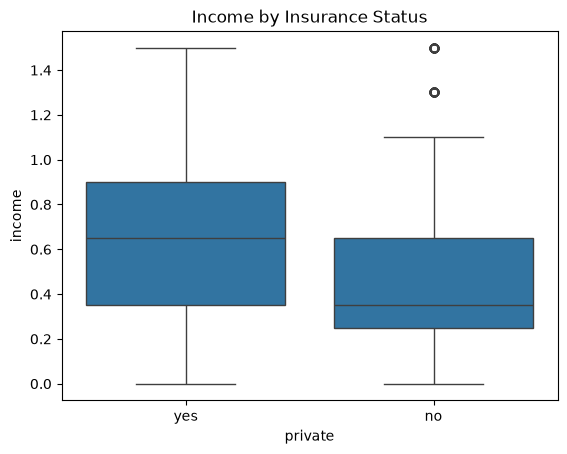

In [26]:
sns.boxplot(x="private", y="income", data=data)
plt.title("Income by Insurance Status")
plt.show()

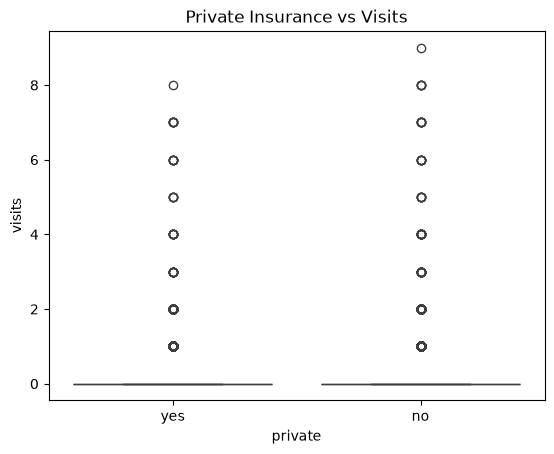

In [28]:
sns.boxplot(x="private", y="visits", data=data)
plt.title("Private Insurance vs Visits")
plt.show()


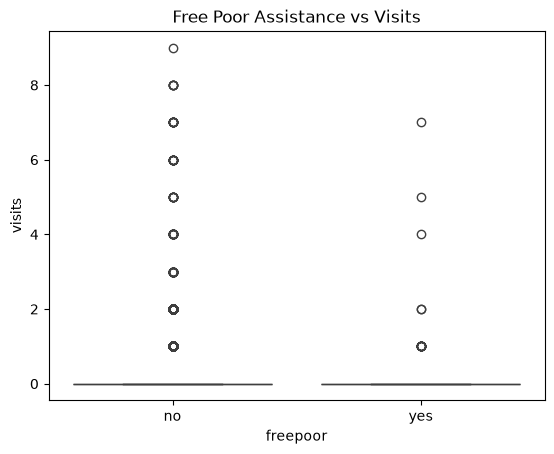

In [29]:
sns.boxplot(x="freepoor", y="visits", data=data)
plt.title("Free Poor Assistance vs Visits")
plt.show()

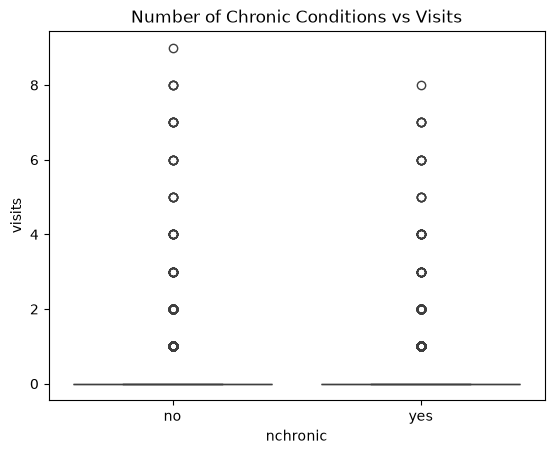

In [30]:
sns.boxplot(x="nchronic", y="visits", data=data)
plt.title("Number of Chronic Conditions vs Visits")
plt.show()

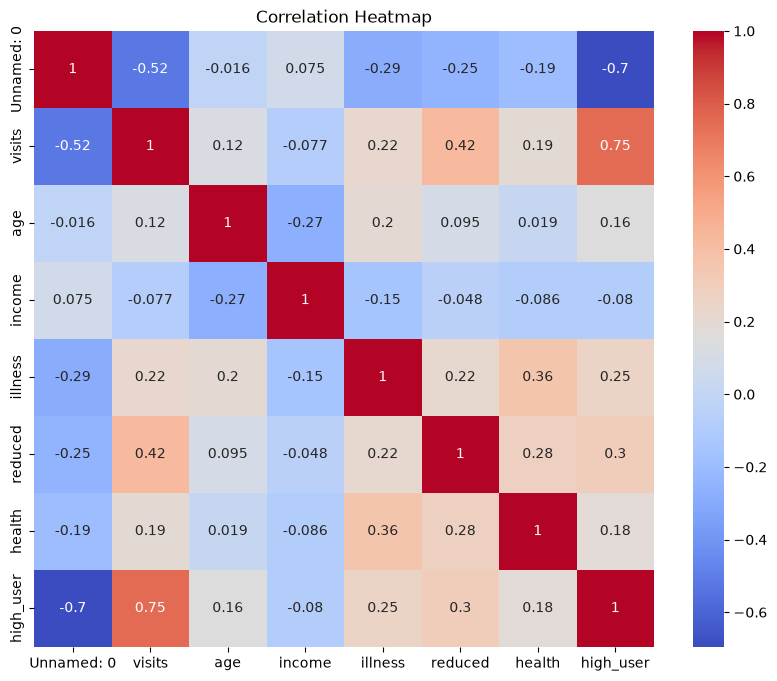

In [31]:

 
corr = data.corr(numeric_only=True)
 
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

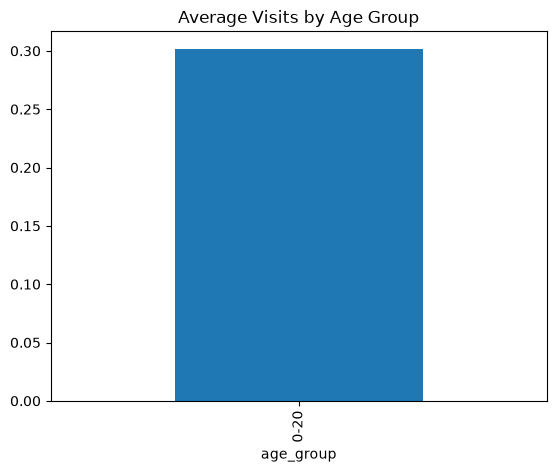

In [32]:

data["age_group"] = pd.cut(
data["age"],
bins=[0,20,40,60,80,100],
labels=["0-20","21-40","41-60","61-80","80+"]
)
 
data.groupby("age_group")["visits"].mean().plot(kind="bar")
plt.title("Average Visits by Age Group")
plt.show()

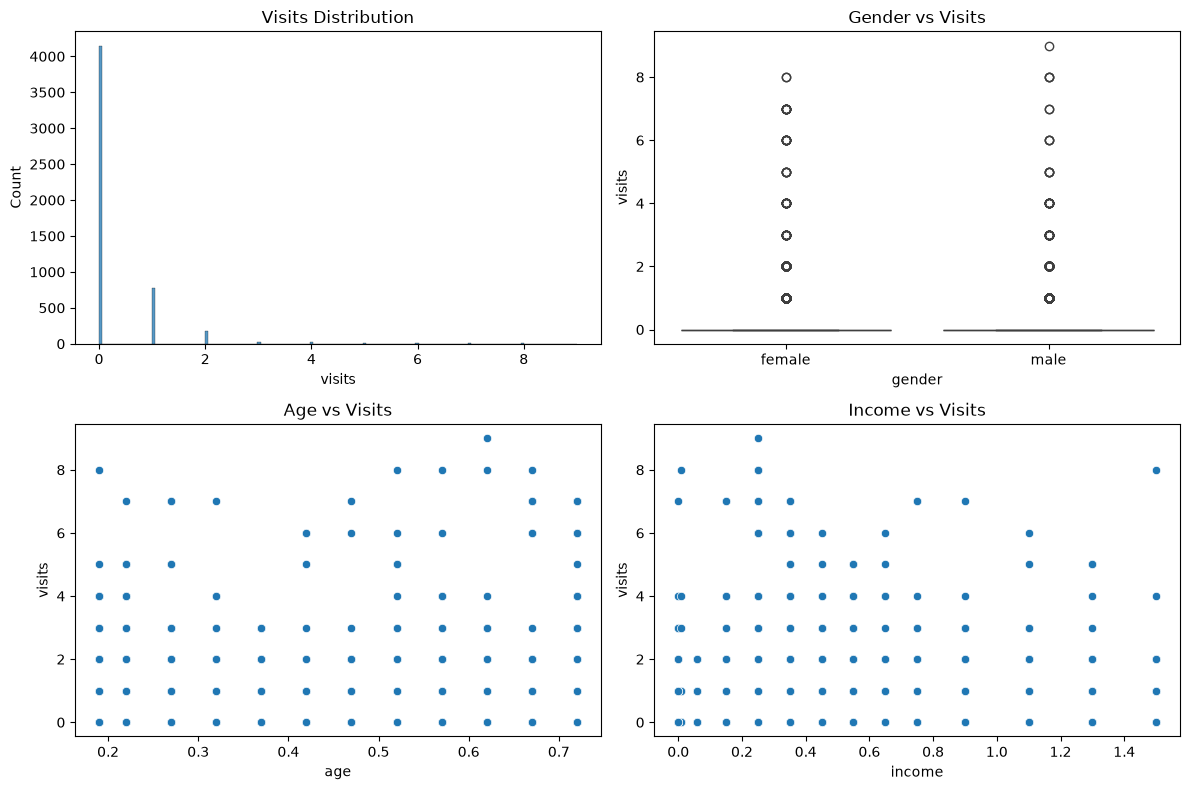

In [33]:
fig, axes = plt.subplots(2,2, figsize=(12,8))
 
sns.histplot(data["visits"], ax=axes[0,0])
axes[0,0].set_title("Visits Distribution")
 
sns.boxplot(x="gender", y="visits", data=data, ax=axes[0,1])
axes[0,1].set_title("Gender vs Visits")
 
sns.scatterplot(x="age", y="visits", data=data, ax=axes[1,0])
axes[1,0].set_title("Age vs Visits")
 
sns.scatterplot(x="income", y="visits", data=data, ax=axes[1,1])
axes[1,1].set_title("Income vs Visits")
 
plt.tight_layout()
plt.show()